In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import time

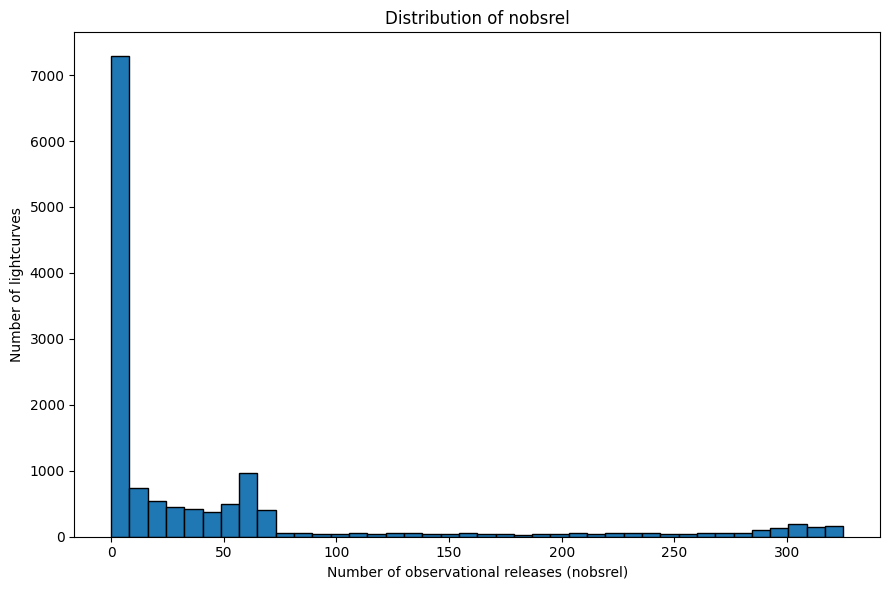

Maximum nobsrel: 325

Top 15 lightcurves:
                oid filtercode  nobsrel  nobs
0   358216400017466         zr      325   444
1   358216400031243         zr      325   444
2   358216400017735         zr      325   444
3   358216400017210         zr      325   444
4   358216400017948         zr      325   444
5   358216400017429         zr      325   444
6   358216400016666         zr      325   444
7   358216400016494         zr      325   444
8   358216400016634         zr      325   444
9   358216400016822         zr      325   444
10  358216400016776         zr      325   444
11  358216400016482         zr      325   444
12  358216400034085         zr      325   444
13  358216400017566         zr      325   444
14  358216400017724         zr      325   444


In [3]:
# --------------------------------------------------
# 1. Read the IRSA/IPAC table
# --------------------------------------------------

filename = r"C:\Users\marya\Downloads\table_irsa_catalog_search_results.tbl"

# The actual data in this file starts after the IPAC metadata/header.
# Define the fixed-width column positions from the table.
with open(filename, "r") as f:
    lines = f.readlines()

# Find the line containing the column names
header_idx = next(
    i for i, line in enumerate(lines)
    if line.startswith("|oid")
)

header = lines[header_idx].rstrip("\n")

# Positions of the "|" separators
bars = [i for i, char in enumerate(header) if char == "|"]

# Column names
columns = [
    header[a + 1:b].strip()
    for a, b in zip(bars[:-1], bars[1:])
]

# Fixed-width positions
spans = [
    (a + 1, b)
    for a, b in zip(bars[:-1], bars[1:])
]

# Data begins after the 4 IPAC header rows
data_lines = lines[header_idx + 4:]

records = []

for line in data_lines:
    if not line.strip():
        continue

    record = {}

    for column, (start, end) in zip(columns, spans):
        record[column] = line[start:end].strip()

    records.append(record)

df = pd.DataFrame(records)


# --------------------------------------------------
# 2. Convert numerical columns
# --------------------------------------------------

# Keep filtercode as text; convert everything else to numbers
for col in df.columns:
    if col != "filtercode":
        df[col] = pd.to_numeric(df[col], errors="coerce")


# --------------------------------------------------
# 3. Histogram of nobsrel
# --------------------------------------------------

plt.figure(figsize=(9, 6))

plt.hist(
    df["nobsrel"].dropna(),
    bins=40,
    edgecolor="black"
)

plt.xlabel("Number of observational releases (nobsrel)")
plt.ylabel("Number of lightcurves")
plt.title("Distribution of nobsrel")

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 4. Maximum number of points
# --------------------------------------------------

max_nobsrel = df["nobsrel"].max()

print("Maximum nobsrel:", max_nobsrel)


# --------------------------------------------------
# 5. Select top 15 lightcurves
# --------------------------------------------------

top15 = (
    df.nlargest(15, "nobsrel")
      [["oid", "filtercode", "nobsrel", "nobs"]]
      .reset_index(drop=True)
)

print("\nTop 15 lightcurves:")
print(top15)

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import time


# ============================================================
# 1. SELECT TOP 15 OIDs BY nobsrel
# ============================================================

top15 = (
    df.sort_values("nobsrel", ascending=False)
      .head(15)
      .copy()
)

top15_oids = top15["oid"].astype("int64").tolist()


# ============================================================
# 2. CREATE ONLY THE PLOT FOLDER
# ============================================================

os.makedirs("top15_lightcurve_plots", exist_ok=True)


# ============================================================
# 3. DOWNLOAD AND PLOT EACH OID
# ============================================================

for oid in top15_oids:

    url = (
        "https://irsa.ipac.caltech.edu/cgi-bin/ZTF/nph_light_curves"
        f"?ID={oid}&FORMAT=csv"
    )

    try:
        lc = pd.read_csv(url)

    except Exception as e:
        print(f"Could not download OID {oid}: {e}")
        continue


    # Convert needed columns to numeric
    for col in ["mjd", "mag", "magerr"]:
        lc[col] = pd.to_numeric(
            lc[col],
            errors="coerce"
        )


    # Remove rows with missing plotting values
    lc_plot = lc.dropna(
        subset=["mjd", "mag", "magerr"]
    ).copy()


    if len(lc_plot) == 0:
        print(f"No valid data for OID {oid}")
        continue


    # ========================================================
    # MAKE LIGHTCURVE
    # ========================================================

    fig, ax = plt.subplots(figsize=(11, 6))

    ax.errorbar(
        lc_plot["mjd"],
        lc_plot["mag"],
        yerr=lc_plot["magerr"],
        fmt=".",
        markersize=5,
        capsize=2,
        elinewidth=0.8,
        alpha=0.8,


    )


    # Mark MJD = 59988
    ax.axvline(
        x=59988,
        linestyle="--",
        linewidth=1.5,
        label="MJD = 59988"
    )


    # Smaller magnitude = brighter
    ax.invert_yaxis()

    ax.set_xlabel(
        "Modified Julian Date (MJD)"
    )

    ax.set_ylabel(
        "Magnitude"
    )


    # Get nobsrel for this OID
    nobsrel = top15.loc[
        top15["oid"].astype("int64") == oid,
        "nobsrel"
    ].iloc[0]


    ax.set_title(
        f"ZTF Lightcurve - OID {oid}\n"
        f"nobsrel = {nobsrel} | "
        f"N = {len(lc_plot)}"
    )

    ax.grid(
        alpha=0.3,
        linestyle="--"
    )

    ax.legend()

    fig.tight_layout()


    # ========================================================
    # SAVE PLOT ONLY
    # ========================================================

    plot_filename = (
        f"top15_lightcurve_plots/"
        f"OID_{oid}_lightcurve.png"
    )

    fig.savefig(
        plot_filename,
        dpi=300,
        bbox_inches="tight"
    )

    # Do not display the plot
    plt.close(fig)

    print(f"Saved OID {oid}")


    # Small delay between IRSA requests
    time.sleep(0.5)


print("Done - all lightcurves saved.")

Saved OID 358216400015816
Saved OID 358216400016229
Saved OID 358216400015442
Saved OID 358216400017210
Saved OID 358216400031243
Saved OID 358216400015904
Saved OID 358216400016351
Saved OID 358216400016666
Saved OID 358216400015432
Saved OID 358216400015617
Saved OID 358216400016890
Saved OID 358216400016494
Saved OID 358216400016634
Saved OID 358216400017522
Saved OID 358216400015902
Done - all lightcurves saved.


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import time

from astropy.stats import sigma_clip, mad_std


# ============================================================
# SETTINGS
# ============================================================

EVENT_MJD = 59988

os.makedirs("top15_lightcurve_fvar", exist_ok=True)


# ============================================================
# FUNCTION TO CALCULATE Fvar
# EXACT SAME PROCEDURE AS YOUR EXAMPLE
# ============================================================

def calculate_fvar(mag, magerr):

    mag = np.asarray(mag, dtype=float)
    magerr = np.asarray(magerr, dtype=float)

    # --------------------------------------------------------
    # Convert magnitude to relative flux
    # --------------------------------------------------------

    flux = 10**(-0.4 * mag)


    # --------------------------------------------------------
    # Propagate magnitude uncertainty to flux uncertainty
    #
    # sigma_F = 0.4 ln(10) F sigma_mag
    # --------------------------------------------------------

    flux_err = (
        0.4
        * np.log(10)
        * flux
        * magerr
    )


    x = flux
    sigma_err = flux_err

    N = len(x)

    if N < 2:
        return np.nan, np.nan


    # ========================================================
    # Quantities in Equation (1)
    # ========================================================

    mean_x = np.mean(x)

    S2 = np.var(
        x,
        ddof=1
    )

    mean_sigma_err2 = np.mean(
        sigma_err**2
    )


    # ========================================================
    # Equation (1)
    # ========================================================

    excess_variance = (
        S2
        - mean_sigma_err2
    )


    # Fvar is not real if excess variance <= 0
    if excess_variance <= 0:
        return np.nan, np.nan


    Fvar = np.sqrt(
        excess_variance
        / mean_x**2
    )


    # ========================================================
    # Equation (3)
    # ========================================================

    err_sigma_NXS2 = np.sqrt(

        (
            np.sqrt(2 / N)
            * mean_sigma_err2
            / mean_x**2
        )**2

        +

        (
            np.sqrt(mean_sigma_err2 / N)
            * 2
            * Fvar
            / mean_x
        )**2

    )


    # ========================================================
    # Equation (2)
    # ========================================================

    Fvar_err = (
        np.sqrt(
            Fvar**2
            + err_sigma_NXS2
        )
        - Fvar
    )


    return Fvar, Fvar_err


# ============================================================
# SELECT TOP 15 OIDs BY nobsrel
# ============================================================

top15 = (
    df.sort_values(
        "nobsrel",
        ascending=False
    )
    .head(15)
    .copy()
)


top15_oids = (
    top15["oid"]
    .astype("int64")
    .tolist()
)


# ============================================================
# LOOP THROUGH THE 15 SOURCES
# ============================================================

for oid in top15_oids:

    # --------------------------------------------------------
    # Download ZTF lightcurve
    # --------------------------------------------------------

    url = (
        "https://irsa.ipac.caltech.edu/cgi-bin/ZTF/nph_light_curves"
        f"?ID={oid}&FORMAT=csv"
    )

    try:
        lc = pd.read_csv(url)

    except Exception as e:
        print(f"Could not download OID {oid}: {e}")
        continue


    # ========================================================
    # CLEAN MJD, MAG, MAGERR
    # ========================================================

    lc = lc[
        ["mjd", "mag", "magerr"]
    ].copy()


    lc["mjd"] = pd.to_numeric(
        lc["mjd"],
        errors="coerce"
    )

    lc["mag"] = pd.to_numeric(
        lc["mag"],
        errors="coerce"
    )

    lc["magerr"] = pd.to_numeric(
        lc["magerr"],
        errors="coerce"
    )


    # Remove NaN
    lc = lc.dropna()


    # Remove infinite / invalid values
    lc = lc[
        np.isfinite(lc["mjd"])
        & np.isfinite(lc["mag"])
        & np.isfinite(lc["magerr"])
        & (lc["magerr"] > 0)
    ].copy()


    # Sort by time
    lc = lc.sort_values("mjd")


    if len(lc) < 2:
        print(f"Not enough valid data for OID {oid}")
        continue


    # ========================================================
    # ORIGINAL LIGHTCURVE
    # NO 3-SIGMA CORRECTION
    # ========================================================

    n_original = len(lc)


    Fvar_original, Fvar_err_original = calculate_fvar(

        lc["mag"].to_numpy(),

        lc["magerr"].to_numpy()
    )


    # ========================================================
    # 3-SIGMA CLIPPING
    #
    # SAME AS YOUR EXISTING CODE
    # ========================================================

    clipped = sigma_clip(

        lc["mag"].to_numpy(),

        sigma=3,

        maxiters=None,

        cenfunc="median",

        stdfunc=mad_std
    )


    # True means rejected by sigma clipping
    rejected_mask = np.ma.getmaskarray(
        clipped
    )


    # Keep only surviving measurements
    lc_clipped = lc.loc[
        ~rejected_mask
    ].copy()


    # ========================================================
    # NUMBER REMOVED
    # ========================================================

    n_after = len(lc_clipped)

    n_removed = (
        n_original
        - n_after
    )


    # ========================================================
    # Fvar AFTER 3-SIGMA CLIPPING
    # ========================================================

    Fvar_clipped, Fvar_err_clipped = calculate_fvar(

        lc_clipped["mag"].to_numpy(),

        lc_clipped["magerr"].to_numpy()
    )


    # ========================================================
    # MAKE THE TWO-PANEL FIGURE
    # ========================================================

    fig, (ax1, ax2) = plt.subplots(

        2,
        1,

        figsize=(12, 10),

        sharex=True
    )


    # ========================================================
    # TOP:
    # ORIGINAL / NO SIGMA CLIPPING
    # ========================================================

    ax1.errorbar(

        lc["mjd"],

        lc["mag"],

        yerr=lc["magerr"],

        fmt=".",

        markersize=5,

        capsize=2,

        elinewidth=0.8,

        alpha=0.8,
    )


    # Mark MJD 59988
    ax1.axvline(

        EVENT_MJD,

        linestyle="--",

        linewidth=1.5,

        label=f"MJD = {EVENT_MJD}"
    )


    # Magnitude convention
    ax1.invert_yaxis()


    ax1.set_ylabel(
        "Magnitude"
    )


    ax1.set_title(
        f"OID {oid} - No 3σ Correction"
    )


    ax1.grid(
        alpha=0.3,
        linestyle="--"
    )


    ax1.legend()


    # --------------------------------------------------------
    # Fvar information
    # --------------------------------------------------------

    original_text = (
    f"N = {n_original}\n"
    f"$F_{{var}}$ = {Fvar_original:.4f} "
    f"$\\pm$ {Fvar_err_original:.4f}"
    )


    ax1.text(

        0.02,
        0.97,

        original_text,

        transform=ax1.transAxes,

        verticalalignment="top",
        color="Black",
        bbox=dict(
            boxstyle="round",
            alpha=0.8,
            facecolor="white",
            edgecolor="grey"
        )
    )


    # ========================================================
    # BOTTOM:
    # AFTER 3-SIGMA CLIPPING
    # ========================================================

    ax2.errorbar(

        lc_clipped["mjd"],

        lc_clipped["mag"],

        yerr=lc_clipped["magerr"],

        fmt=".",

        markersize=5,

        capsize=2,

        elinewidth=0.8,

        alpha=0.8,
    )


    ax2.axvline(

        EVENT_MJD,

        linestyle="--",

        linewidth=1.5,

        label=f"MJD = {EVENT_MJD}"
    )


    ax2.invert_yaxis()


    ax2.set_xlabel(
        "Modified Julian Date (MJD)"
    )


    ax2.set_ylabel(
        "Magnitude"
    )


    ax2.set_title(
        f"OID {oid} - After 3σ Correction"
    )


    ax2.grid(
        alpha=0.3,
        linestyle="--"
    )


    ax2.legend()


    # --------------------------------------------------------
    # Fvar + clipping information
    # --------------------------------------------------------

    clipped_text = (
    f"N = {n_after}\n"
    f"Removed = {n_removed}\n"
    f"$F_{{var}}$ = {Fvar_clipped:.4f} "
    f"$\\pm$ {Fvar_err_clipped:.4f}"
    )

    ax2.text(

        0.02,
        0.97,

        clipped_text,

        transform=ax2.transAxes,

        verticalalignment="top",


        color="black",
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.8, edgecolor="grey")
    )


    # ========================================================
    # SAVE
    # ========================================================

    fig.tight_layout()


    filename = (

        "top15_lightcurve_fvar/"

        f"OID_{oid}_Fvar_comparison.png"
    )


    fig.savefig(

        filename,

        dpi=300,

        bbox_inches="tight"
    )


    # Do not display in PyCharm
    plt.close(fig)


    # ========================================================
    # PRINT NUMBERS
    # ========================================================

    print(f"\nOID = {oid}")

    print(
        f"Original: "
        f"N = {n_original}, "
        f"Fvar = {Fvar_original:.6f}, "
        f"error = {Fvar_err_original:.6f}"
    )

    print(
        f"3-sigma:  "
        f"N = {n_after}, "
        f"removed = {n_removed}, "
        f"Fvar = {Fvar_clipped:.6f}, "
        f"error = {Fvar_err_clipped:.6f}"
    )


    time.sleep(0.5)


print("\nDone.")


OID = 358216400015816
Original: N = 325, Fvar = 0.061755, error = 0.000626
3-sigma:  N = 306, removed = 19, Fvar = 0.011241, error = 0.000761

OID = 358216400016229
Original: N = 325, Fvar = 0.057784, error = 0.000424
3-sigma:  N = 304, removed = 21, Fvar = 0.007996, error = 0.000512

OID = 358216400015442
Original: N = 325, Fvar = 0.058407, error = 0.000549
3-sigma:  N = 307, removed = 18, Fvar = 0.009157, error = 0.000683

OID = 358216400017210
Original: N = 325, Fvar = 0.062982, error = 0.000502
3-sigma:  N = 302, removed = 23, Fvar = 0.008658, error = 0.000624

OID = 358216400031243
Original: N = 325, Fvar = 0.062008, error = 0.000422
3-sigma:  N = 314, removed = 11, Fvar = 0.020434, error = 0.000438

OID = 358216400015904
Original: N = 325, Fvar = 0.064521, error = 0.000528
3-sigma:  N = 308, removed = 17, Fvar = 0.010425, error = 0.000626

OID = 358216400016351
Original: N = 325, Fvar = 0.054431, error = 0.000577
3-sigma:  N = 309, removed = 16, Fvar = 0.011786, error = 0.000675

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import time

from astropy.stats import sigma_clip, mad_std

# Force a light plot style even when PyCharm uses a dark theme or a
# dark Matplotlib style was activated in an earlier notebook cell.
plt.style.use("default")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "savefig.transparent": False,
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.titlecolor": "black",
    "axes.edgecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "grid.color": "#b0b0b0",
})

LIGHTCURVE_COLOR = "#1f77b4"

# ============================================================
# SETTINGS
# ============================================================

EVENT_MJD = 59988

os.makedirs("top15_lightcurve_fvar", exist_ok=True)


# ============================================================
# FUNCTION TO CALCULATE Fvar
# EXACT SAME PROCEDURE AS YOUR EXAMPLE
# ============================================================

def calculate_fvar(mag, magerr):
    mag = np.asarray(mag, dtype=float)
    magerr = np.asarray(magerr, dtype=float)

    # --------------------------------------------------------
    # Convert magnitude to relative flux
    # --------------------------------------------------------

    flux = 10 ** (-0.4 * mag)

    # --------------------------------------------------------
    # Propagate magnitude uncertainty to flux uncertainty
    #
    # sigma_F = 0.4 ln(10) F sigma_mag
    # --------------------------------------------------------

    flux_err = (
            0.4
            * np.log(10)
            * flux
            * magerr
    )

    x = flux
    sigma_err = flux_err

    N = len(x)

    if N < 2:
        return np.nan, np.nan

    # ========================================================
    # Quantities in Equation (1)
    # ========================================================

    mean_x = np.mean(x)

    S2 = np.var(
        x,
        ddof=1
    )

    mean_sigma_err2 = np.mean(
        sigma_err ** 2
    )

    # ========================================================
    # Equation (1)
    # ========================================================

    excess_variance = (
            S2
            - mean_sigma_err2
    )

    # Fvar is not real if excess variance <= 0
    if excess_variance <= 0:
        return np.nan, np.nan

    Fvar = np.sqrt(
        excess_variance
        / mean_x ** 2
    )

    # ========================================================
    # Equation (3)
    # ========================================================

    err_sigma_NXS2 = np.sqrt(

        (
                np.sqrt(2 / N)
                * mean_sigma_err2
                / mean_x ** 2
        ) ** 2

        +

        (
                np.sqrt(mean_sigma_err2 / N)
                * 2
                * Fvar
                / mean_x
        ) ** 2

    )

    # ========================================================
    # Equation (2)
    # ========================================================

    Fvar_err = (
            np.sqrt(
                Fvar ** 2
                + err_sigma_NXS2
            )
            - Fvar
    )

    return Fvar, Fvar_err


# ============================================================
# SELECT TOP 15 OIDs BY nobsrel
# ============================================================

top15 = (
    df.sort_values(
        "nobsrel",
        ascending=False
    )
    .head(15)
    .copy()
)

top15_oids = (
    top15["oid"]
    .astype("int64")
    .tolist()
)

# ============================================================
# LOOP THROUGH THE 15 SOURCES
# ============================================================

for oid in top15_oids:

    # --------------------------------------------------------
    # Download ZTF lightcurve
    # --------------------------------------------------------

    url = (
        "https://irsa.ipac.caltech.edu/cgi-bin/ZTF/nph_light_curves"
        f"?ID={oid}&FORMAT=csv"
    )

    try:
        lc = pd.read_csv(url)

    except Exception as e:
        print(f"Could not download OID {oid}: {e}")
        continue

    # ========================================================
    # CLEAN MJD, MAG, MAGERR
    # ========================================================

    lc = lc[
        ["mjd", "mag", "magerr"]
    ].copy()

    lc["mjd"] = pd.to_numeric(
        lc["mjd"],
        errors="coerce"
    )

    lc["mag"] = pd.to_numeric(
        lc["mag"],
        errors="coerce"
    )

    lc["magerr"] = pd.to_numeric(
        lc["magerr"],
        errors="coerce"
    )

    # Remove NaN
    lc = lc.dropna()

    # Remove infinite / invalid values
    lc = lc[
        np.isfinite(lc["mjd"])
        & np.isfinite(lc["mag"])
        & np.isfinite(lc["magerr"])
        & (lc["magerr"] > 0)
        ].copy()

    # Sort by time
    lc = lc.sort_values("mjd")

    if len(lc) < 2:
        print(f"Not enough valid data for OID {oid}")
        continue

    # ========================================================
    # ORIGINAL LIGHTCURVE
    # NO 3-SIGMA CORRECTION
    # ========================================================

    n_original = len(lc)

    Fvar_original, Fvar_err_original = calculate_fvar(

        lc["mag"].to_numpy(),

        lc["magerr"].to_numpy()
    )

    # ========================================================
    # 3-SIGMA CLIPPING
    #
    # SAME AS YOUR EXISTING CODE
    # ========================================================

    clipped = sigma_clip(

        lc["mag"].to_numpy(),

        sigma=3,

        maxiters=None,

        cenfunc="median",

        stdfunc=mad_std
    )

    # True means rejected by sigma clipping
    rejected_mask = np.ma.getmaskarray(
        clipped
    )

    # Keep only surviving measurements
    lc_clipped = lc.loc[
        ~rejected_mask
    ].copy()

    # ========================================================
    # NUMBER REMOVED
    # ========================================================

    n_after = len(lc_clipped)

    n_removed = (
            n_original
            - n_after
    )

    # ========================================================
    # Fvar AFTER 3-SIGMA CLIPPING
    # ========================================================

    Fvar_clipped, Fvar_err_clipped = calculate_fvar(

        lc_clipped["mag"].to_numpy(),

        lc_clipped["magerr"].to_numpy()
    )

    # ========================================================
    # MAKE THE TWO-PANEL FIGURE
    # ========================================================

    fig, (ax1, ax2) = plt.subplots(

        2,
        1,

        figsize=(12, 10),

        sharex=True,

        facecolor="white"
    )

    # Set the canvas and both plotting panels explicitly to white.
    fig.patch.set_facecolor("white")
    ax1.set_facecolor("white")
    ax2.set_facecolor("white")

    # ========================================================
    # TOP:
    # ORIGINAL / NO SIGMA CLIPPING
    # ========================================================

    ax1.errorbar(

        lc["mjd"],

        lc["mag"],

        yerr=lc["magerr"],

        fmt=".",

        markersize=5,

        capsize=2,

        elinewidth=0.8,

        alpha=0.8,

        color=LIGHTCURVE_COLOR,

        ecolor=LIGHTCURVE_COLOR,

        markerfacecolor=LIGHTCURVE_COLOR,

        markeredgecolor=LIGHTCURVE_COLOR,
    )

    # Mark MJD 59988
    ax1.axvline(

        EVENT_MJD,

        color="black",

        linestyle="--",

        linewidth=1.5,

        label=f"MJD = {EVENT_MJD}"
    )

    # Magnitude convention
    ax1.invert_yaxis()

    ax1.set_ylabel(
        "Magnitude"
    )

    ax1.set_title(
        f"OID {oid} - No 3σ Correction"
    )

    ax1.grid(
        True,

        color="#b0b0b0",

        alpha=0.3,
        linestyle="--"
    )

    legend1 = ax1.legend(
        facecolor="white",
        edgecolor="grey",
        framealpha=1
    )

    for legend_text in legend1.get_texts():
        legend_text.set_color("black")

    # --------------------------------------------------------
    # Fvar information
    # --------------------------------------------------------

    original_text = (
        f"N = {n_original}\n"
        f"$F_{{var}}$ = {Fvar_original:.4f} "
        f"$\\pm$ {Fvar_err_original:.4f}"
    )

    ax1.text(

        0.02,
        0.97,

        original_text,

        transform=ax1.transAxes,

        verticalalignment="top",
        color="Black",
        bbox=dict(
            boxstyle="round",
            alpha=0.8,
            facecolor="white",
            edgecolor="grey"
        )
    )

    # ========================================================
    # BOTTOM:
    # AFTER 3-SIGMA CLIPPING
    # ========================================================

    ax2.errorbar(

        lc_clipped["mjd"],

        lc_clipped["mag"],

        yerr=lc_clipped["magerr"],

        fmt=".",

        markersize=5,

        capsize=2,

        elinewidth=0.8,

        alpha=0.8,

        color=LIGHTCURVE_COLOR,

        ecolor=LIGHTCURVE_COLOR,

        markerfacecolor=LIGHTCURVE_COLOR,

        markeredgecolor=LIGHTCURVE_COLOR,
    )

    ax2.axvline(

        EVENT_MJD,

        color="black",

        linestyle="--",

        linewidth=1.5,

        label=f"MJD = {EVENT_MJD}"
    )

    ax2.invert_yaxis()

    ax2.set_xlabel(
        "Modified Julian Date (MJD)"
    )

    ax2.set_ylabel(
        "Magnitude"
    )

    ax2.set_title(
        f"OID {oid} - After 3σ Correction"
    )

    ax2.grid(
        True,

        color="#b0b0b0",

        alpha=0.3,
        linestyle="--"
    )

    legend2 = ax2.legend(
        facecolor="white",
        edgecolor="grey",
        framealpha=1
    )

    for legend_text in legend2.get_texts():
        legend_text.set_color("black")

    # --------------------------------------------------------
    # Fvar + clipping information
    # --------------------------------------------------------

    clipped_text = (
        f"N = {n_after}\n"
        f"Removed = {n_removed}\n"
        f"$F_{{var}}$ = {Fvar_clipped:.4f} "
        f"$\\pm$ {Fvar_err_clipped:.4f}"
    )

    ax2.text(

        0.02,
        0.97,

        clipped_text,

        transform=ax2.transAxes,

        verticalalignment="top",

        color="black",
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.8, edgecolor="grey")
    )

    # ========================================================
    # SAVE
    # ========================================================

    fig.tight_layout()

    filename = (

        "top15_lightcurve_fvar/"

        f"OID_{oid}_Fvar_comparison.png"
    )

    fig.savefig(

        filename,

        dpi=300,

        bbox_inches="tight",

        facecolor="white",

        edgecolor="white",

        transparent=False
    )

    # Do not display in PyCharm
    plt.close(fig)

    # ========================================================
    # PRINT NUMBERS
    # ========================================================

    print(f"\nOID = {oid}")

    print(
        f"Original: "
        f"N = {n_original}, "
        f"Fvar = {Fvar_original:.6f}, "
        f"error = {Fvar_err_original:.6f}"
    )

    print(
        f"3-sigma:  "
        f"N = {n_after}, "
        f"removed = {n_removed}, "
        f"Fvar = {Fvar_clipped:.6f}, "
        f"error = {Fvar_err_clipped:.6f}"
    )

    time.sleep(0.5)

print("\nDone.")


OID = 358216400015816
Original: N = 325, Fvar = 0.061755, error = 0.000626
3-sigma:  N = 306, removed = 19, Fvar = 0.011241, error = 0.000761

OID = 358216400016229
Original: N = 325, Fvar = 0.057784, error = 0.000424
3-sigma:  N = 304, removed = 21, Fvar = 0.007996, error = 0.000512

OID = 358216400015442
Original: N = 325, Fvar = 0.058407, error = 0.000549
3-sigma:  N = 307, removed = 18, Fvar = 0.009157, error = 0.000683

OID = 358216400017210
Original: N = 325, Fvar = 0.062982, error = 0.000502
3-sigma:  N = 302, removed = 23, Fvar = 0.008658, error = 0.000624

OID = 358216400031243
Original: N = 325, Fvar = 0.062008, error = 0.000422
3-sigma:  N = 314, removed = 11, Fvar = 0.020434, error = 0.000438

OID = 358216400015904
Original: N = 325, Fvar = 0.064521, error = 0.000528
3-sigma:  N = 308, removed = 17, Fvar = 0.010425, error = 0.000626

OID = 358216400016351
Original: N = 325, Fvar = 0.054431, error = 0.000577
3-sigma:  N = 309, removed = 16, Fvar = 0.011786, error = 0.000675